In [1]:
# Cell 1: Import libraries

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

import joblib

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Cell 2: Locate and load the existing dataset

possible_paths = [
    Path("../data/customer-churn-training.csv"),
    Path("data/customer-churn-training.csv"),
    Path("../../data/customer-churn-training.csv")
]

data_path = next(
    (p for p in possible_paths if p.exists()),
    None
)

if data_path is None:
    raise FileNotFoundError(
        "customer-churn-training.csv not found. "
        "Check your project data folder and notebook location."
    )

df = pd.read_csv(data_path)
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Dataset:", data_path.resolve())
print("Shape:", df.shape)

display(df.head(12))
print("\nTarget distribution:")
display(df["churned"].value_counts().sort_index())

Dataset: D:\INTERNSHIP WORK\RabTech-AI-ML-Internship\data\customer-churn-training.csv
Shape: (12, 7)


,customer_id,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,churned
0,C001,2,4,499,21,Basic,1
1,C002,18,1,1299,2,Pro,0
2,C003,6,3,799,14,Basic,1
3,C004,30,0,1499,1,Pro,0
4,C005,11,2,999,5,Standard,0
5,C006,1,5,499,30,Basic,1
6,C007,24,1,999,3,Standard,0
7,C008,8,4,799,17,Basic,1
8,C009,15,2,1299,4,Pro,0
9,C010,4,3,499,12,Basic,1



Target distribution:


churned
0    7
1    5
Name: count, dtype: int64

In [3]:
# Cell 3: Exclude customer ID and separate target

df = df.drop_duplicates().copy()
df = df.dropna(subset=["churned"])

X = df.drop(columns=["customer_id", "churned"])
y = df["churned"].astype(int)

numeric_features = [
    "tenure_months",
    "support_tickets",
    "monthly_spend_inr",
    "last_login_days"
]

categorical_features = ["plan_type"]

# Hold out the test set before tuning or fitting preprocessing.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training records:", len(X_train))
print("Test records:", len(X_test))
print("\nTraining target counts:")
display(y_train.value_counts().sort_index())

print("\nTest target counts:")
display(y_test.value_counts().sort_index())

Training records: 9
Test records: 3

Training target counts:


churned
0    5
1    4
Name: count, dtype: int64


Test target counts:


churned
0    2
1    1
Name: count, dtype: int64

In [4]:
# Cell 4: Preprocessing fitted only inside each CV training fold

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline ready.")

Preprocessing pipeline ready.


In [5]:
# Cell 5: Four different classifiers and their search spaces

model_configs = {
    "Logistic Regression": {
        "estimator": LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ),
        "params": {
            "model__C": [0.1, 1.0, 10.0]
        }
    },

    "Random Forest": {
        "estimator": RandomForestClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE
        ),
        "params": {
            "model__n_estimators": [50, 100],
            "model__max_depth": [None, 3, 5],
            "model__min_samples_leaf": [1, 2]
        }
    },

    "Extra Trees": {
        "estimator": ExtraTreesClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE
        ),
        "params": {
            "model__n_estimators": [50, 100],
            "model__max_depth": [None, 3, 5],
            "model__min_samples_leaf": [1, 2]
        }
    },

    "Support Vector Machine": {
        "estimator": SVC(
            probability=True,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ),
        "params": {
            "model__C": [0.1, 1.0, 10.0],
            "model__kernel": ["linear", "rbf"]
        }
    }
}

print("Number of model architectures:", len(model_configs))
print(*model_configs.keys(), sep="\n")

Number of model architectures: 4
Logistic Regression
Random Forest
Extra Trees
Support Vector Machine


In [6]:
# Cell 6: Stratified 3-fold cross-validation

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

search_results = {}
comparison_rows = []

for model_name, config in model_configs.items():
    print(f"\nTuning: {model_name}")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", config["estimator"])
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=config["params"],
        scoring=scoring,
        refit="f1",
        cv=cv,
        n_jobs=-1,
        error_score="raise",
        return_train_score=False
    )

    search.fit(X_train, y_train)
    search_results[model_name] = search

    best_index = search.best_index_
    best_cv = search.cv_results_

    comparison_rows.append({
        "Model": model_name,
        "Best CV F1": best_cv["mean_test_f1"][best_index],
        "CV Precision": best_cv["mean_test_precision"][best_index],
        "CV Recall": best_cv["mean_test_recall"][best_index],
        "CV ROC-AUC": best_cv["mean_test_roc_auc"][best_index],
        "Best Parameters": search.best_params_
    })

    print("Best CV F1:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

comparison_df = pd.DataFrame(comparison_rows).sort_values(
    by="Best CV F1",
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))


Tuning: Logistic Regression
Best CV F1: 1.0
Best parameters: {'model__C': 0.1}

Tuning: Random Forest
Best CV F1: 1.0
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 50}

Tuning: Extra Trees
Best CV F1: 1.0
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 50}

Tuning: Support Vector Machine
Best CV F1: 1.0
Best parameters: {'model__C': 0.1, 'model__kernel': 'linear'}


,Model,Best CV F1,CV Precision,CV Recall,CV ROC-AUC,Best Parameters
0,Logistic Regression,1.0,1.0,1.0,1.0,{'model__C': 0.1}
1,Random Forest,1.0,1.0,1.0,1.0,"{'model__max_depth': None, 'model__min_samples..."
2,Extra Trees,1.0,1.0,1.0,1.0,"{'model__max_depth': None, 'model__min_samples..."
3,Support Vector Machine,1.0,1.0,1.0,1.0,"{'model__C': 0.1, 'model__kernel': 'linear'}"


In [7]:
# Cell 7: Evaluate each tuned model on the held-out test set

test_rows = []
test_probabilities = {}

for model_name, search in search_results.items():
    best_model = search.best_estimator_

    predictions = best_model.predict(X_test)
    probabilities = best_model.predict_proba(X_test)[:, 1]

    test_probabilities[model_name] = probabilities

    test_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

test_comparison_df = pd.DataFrame(test_rows).sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(test_comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,1.0,1.0,1.0,1.0,1.0
1,Random Forest,1.0,1.0,1.0,1.0,1.0
2,Extra Trees,1.0,1.0,1.0,1.0,1.0
3,Support Vector Machine,1.0,1.0,1.0,1.0,1.0


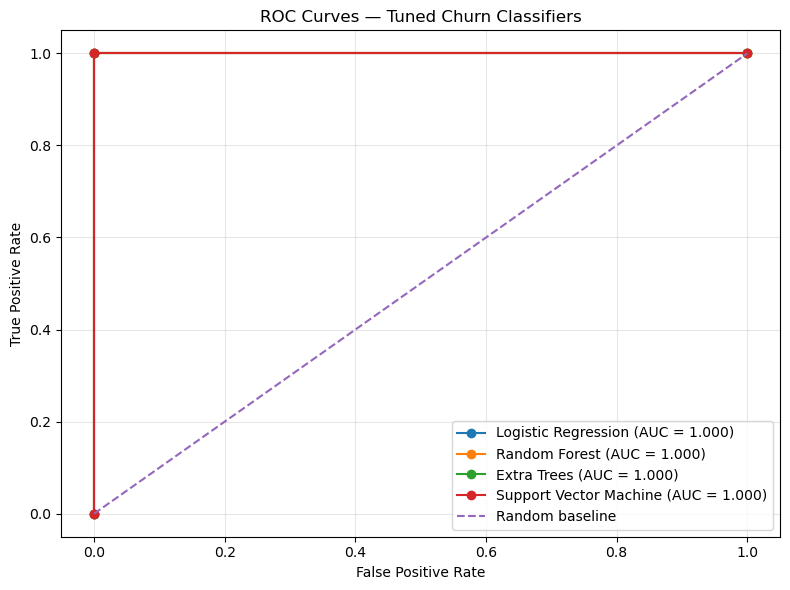

In [8]:
# Cell 8: ROC curves for all tuned models

plt.figure(figsize=(8, 6))

for model_name, probabilities in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc_value = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        marker="o",
        label=f"{model_name} (AUC = {auc_value:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Tuned Churn Classifiers")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Provisional champion: Logistic Regression
Mean CV F1: 1.0

Best hyperparameters:
{'model__C': 0.1}

Test-set classification report:
              precision    recall  f1-score   support

 Not Churned       1.00      1.00      1.00         2
     Churned       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



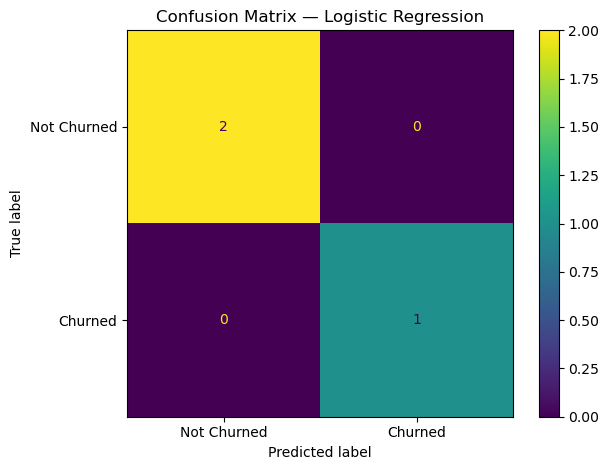

In [9]:
# Cell 9: Select the provisional champion using mean CV F1

champion_name = comparison_df.iloc[0]["Model"]
champion_search = search_results[champion_name]
champion_model = champion_search.best_estimator_

champion_predictions = champion_model.predict(X_test)

print("Provisional champion:", champion_name)
print("Mean CV F1:", round(champion_search.best_score_, 4))
print("\nBest hyperparameters:")
print(champion_search.best_params_)

print("\nTest-set classification report:")
print(classification_report(
    y_test,
    champion_predictions,
    labels=[0, 1],
    target_names=["Not Churned", "Churned"],
    zero_division=0
))

cm = confusion_matrix(y_test, champion_predictions, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Churned", "Churned"]
).plot(values_format="d")

plt.title(f"Confusion Matrix — {champion_name}")
plt.tight_layout()
plt.show()

In [10]:
# Cell 10: Save model comparison and the provisional champion

cwd = Path.cwd()

if cwd.name == "04_Model_Tuning":
    project_root = cwd.parent
elif (cwd / "data" / "customer-churn-training.csv").exists():
    project_root = cwd
else:
    project_root = cwd.parent

tuning_dir = project_root / "04_Model_Tuning"
models_dir = project_root / "models"
reports_dir = project_root / "reports"

tuning_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)

# Save CV and held-out test comparisons
comparison_df.to_csv(
    tuning_dir / "model_comparison.csv",
    index=False
)

test_comparison_df.to_csv(
    reports_dir / "task04_test_model_comparison.csv",
    index=False
)

# Save the selected fitted pipeline, including preprocessing
champion_path = models_dir / "task04_champion_model.joblib"
joblib.dump(champion_model, champion_path)

print("Saved CV comparison:", tuning_dir / "model_comparison.csv")
print("Saved test comparison:", reports_dir / "task04_test_model_comparison.csv")
print("Saved champion model:", champion_path)

print("\nIMPORTANT:")
print("Champion is provisional because the dataset has only 12 records.")

Saved CV comparison: d:\INTERNSHIP WORK\RabTech-AI-ML-Internship\04_Model_Tuning\model_comparison.csv
Saved test comparison: d:\INTERNSHIP WORK\RabTech-AI-ML-Internship\reports\task04_test_model_comparison.csv
Saved champion model: d:\INTERNSHIP WORK\RabTech-AI-ML-Internship\models\task04_champion_model.joblib

IMPORTANT:
Champion is provisional because the dataset has only 12 records.


In [11]:
# Cell 11: Reload the saved model and verify it can predict

loaded_champion = joblib.load(champion_path)

sample_predictions = loaded_champion.predict(X_test)

print("Saved model loaded successfully.")
print("Sample predictions:", sample_predictions.tolist())
print("Actual labels:", y_test.tolist())

Saved model loaded successfully.
Sample predictions: [1, 0, 0]
Actual labels: [1, 0, 0]
